# 05 · Portfolios and risk rules

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/05_portfolio_risk_rules.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

So far every strategy held **one** asset, fully in or fully out. Real portfolios hold many assets in chosen amounts, and real investors set **rules** like *"never fall more than 15% from my peak"*. This notebook builds both, and gets you ready for notebook 06, where an AI model is allowed to manage the portfolio, but only inside these rules.

**What you'll do (~45 min):**
1. Backtest a portfolio of several assets with **weights**
2. Two classic portfolio strategies: **sector rotation** and **dual momentum**
3. Check the **most recent stretch** on its own, and control risk with **volatility targeting**
4. Turn plain-English limits into numbers: **drawdown**, **Value at Risk**
5. Compare three ways to react to a crash: **hold**, **sell everything**, **rotate**
6. Ask *what drove that fall?* and *what if?*

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. From one asset to a portfolio: weights

A **weight** is the share of your money in each asset: `0.25` means a quarter. Weights on a day add up to at most 1, and whatever is left sits in **cash**.

`run_portfolio_backtest(closes, weights)` follows the same rules as `run_backtest`:
- weights decided at a day's close are held **from the next day** (no look-ahead);
- every change of weight pays a trading cost on the size of the change (**turnover**);
- between trades the holdings **drift** with prices, like a real portfolio.

We start with the nine original US **sector funds**: each holds the big companies of one part of the economy (XLK technology, XLE energy, XLU utilities, ...).

In [2]:
from backtester import load_closes
from backtester.portfolio import run_portfolio_backtest, top_n_weights, month_ends, volatility_target
from backtester.metrics import recent_period

SECTORS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
closes = load_closes(SECTORS).dropna()
closes.tail()

,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-10-05,49.50,63.45,53.88,170.10,200.93,81.04,39.97,167.37,110.42
2026-10-06,49.73,63.75,54.01,171.58,202.00,81.80,41.16,167.09,111.72
2026-10-07,48.98,63.36,53.75,167.84,201.39,81.70,41.15,168.81,111.36
2026-10-08,49.27,65.24,54.23,168.40,197.78,83.42,41.07,168.16,111.71
2026-10-09,49.43,65.08,54.73,169.25,198.78,83.43,41.41,170.81,112.85


## 2. Sector rotation: hold the strongest three

**Momentum** says assets that rose recently tend to keep rising for a while. A **sector rotation** strategy ranks the sectors by their last six months (126 trading days) of return, holds the **top three in equal parts**, and re-ranks on the **last trading day of each month**.

This is a **cross-sectional** strategy: it compares assets with each other, instead of comparing one asset with its own past. Much of real quant equity research looks like this.

In [3]:
momentum = closes / closes.shift(126) - 1
rotation_weights = top_n_weights(momentum, n=3, on=month_ends(closes.index))
rotation = run_portfolio_backtest(closes, rotation_weights, cost_bps=5)

print("Held at the end:", rotation_weights.iloc[-1][rotation_weights.iloc[-1] > 0].round(2).to_dict())
rotation.summary()

Held at the end: {'XLE': 0.33, 'XLK': 0.33, 'XLV': 0.33}


,Portfolio,Equal-weight buy & hold
Total return,220.6%,291.6%
Annual return (CAGR),11.5%,13.5%
Annual volatility,17.3%,17.0%
Sharpe ratio,0.71,0.83
Max drawdown,-31.4%,-35.7%


In [4]:
rotation.plot()

<Figure size 1000x700 with 2 Axes>

The benchmark is the fair comparison: **equal parts of all nine sectors, bought on day one and held**.

### Did it still work recently?

A strategy that only looks good over the whole history, and not over its **most recent stretch**, deserves suspicion. `recent_period` scores the **last 20%** of the backtest again, on its own.

In [5]:
recent_period(rotation)

From 2024-08-13,Strategy,Benchmark
Total return,15.8%,41.7%
Annual return (CAGR),7.1%,17.6%
Sharpe ratio,0.53,1.20
Max drawdown,-18.5%,-16.9%


## 3. Dual momentum: the best asset, or cash

**Dual momentum** mixes two ideas:
- **relative** momentum: of a few very different assets (US stocks, tech, small companies, long and medium government bonds, gold), hold the one with the best past year;
- **absolute** momentum: but only while its past year is **above zero**. Otherwise sit in cash.

Cash really did pay interest for much of this period, so this time we let cash earn **3% a year** (`cash_rate=0.03`). Sharpe is then measured *above* that rate, which is the honest way to do it.

In [6]:
ASSETS = ["SPY", "QQQ", "IWM", "TLT", "IEF", "GLD"]
assets = load_closes(ASSETS).dropna()
year_return = assets / assets.shift(252) - 1

best_one = top_n_weights(year_return, n=1, on=month_ends(assets.index))
dual_weights = best_one.where(year_return > 0, 0.0).where(month_ends(assets.index)).ffill().fillna(0.0)

dual = run_portfolio_backtest(assets, dual_weights, cost_bps=5, cash_rate=0.03, benchmark="SPY")
dual.summary()

,Portfolio,SPY buy & hold
Total return,219.3%,360.6%
Annual return (CAGR),11.4%,15.3%
Annual volatility,18.5%,17.7%
Sharpe ratio,0.52,0.73
Max drawdown,-29.6%,-33.7%


In [7]:
held = dual_weights.idxmax(axis=1).where(dual_weights.sum(axis=1) > 0, "cash")
held.loc["2021":"2023"].resample("QE").last().to_frame("held at quarter end")

,held at quarter end
Date,
2021-03-31,IWM
2021-06-30,IWM
2021-09-30,IWM
2021-12-31,SPY
2022-03-31,SPY
2022-06-30,GLD
2022-09-30,cash
2022-12-31,cash
2023-03-31,GLD


Look at 2022: stocks **and** bonds fell together. Dual momentum's absolute rule moved it to cash or gold. That is the whole point of the second rule.

## 4. Volatility targeting: control the risk, not the return

A simple, widely used risk rule: if the portfolio has been bumpy lately, **hold less of it**.

`exposure = min(1, target volatility / recent volatility)`

With a 10% target, a portfolio swinging at 20% a year is held at half size; a calm one stays fully invested. It never borrows to go above 1.

In [8]:
calmer = volatility_target(rotation_weights, closes, target=0.10)
rotation_vt = run_portfolio_backtest(closes, calmer, cost_bps=5)

pd.DataFrame({
    "Sector rotation": rotation.summary()["Portfolio"],
    "Same, volatility targeted": rotation_vt.summary()["Portfolio"],
})

,Sector rotation,"Same, volatility targeted"
Total return,220.6%,98.4%
Annual return (CAGR),11.5%,6.6%
Annual volatility,17.3%,10.2%
Sharpe ratio,0.71,0.67
Max drawdown,-31.4%,-13.1%


Volatility targeting usually changes the **drawdown and volatility** far more than the return. Risk control is a separate decision from picking assets.

## 5. Rules in plain English, as numbers

Say an investor tells you:
> *"Never let my portfolio fall more than **15%** from its peak, and never lose more than **3%** in a single day."*

By the time a limit is hit it is too late, so we watch earlier **warning lines**:

| Line | Value | What happens |
|---|---|---|
| Rotate | half the drawdown limit (7.5%) | move some risk into calmer assets |
| Emergency | 80% of the drawdown limit (12%) | cut risk hard |
| VaR budget | the daily limit (3%) | keep a likely bad day within the limit |

**Value at Risk (VaR)**: the loss you expect to beat on only 1 day in 100. A 99% one-day VaR of 3% means *"on a bad day, expect to lose about 3% or more"*. We estimate it from how much each asset has swung and how they move together, over the last 60 days.

In [9]:
from backtester import risk

limits = risk.Limits(max_drawdown=0.15, max_daily_loss=0.03)
risk.lines_from_limits(limits)

Lines(rotate_at=0.075, emergency_at=0.12, var_budget=0.03, shock_day=0.03)

Now a portfolio that a student might really own: **five big tech holdings in equal parts**. We give it a list of **calm** assets it may move money into: long and medium government bonds, gold, and three steady sectors (consumer staples, utilities, healthcare).

In [10]:
TECH = ["AAPL", "MSFT", "AMZN", "GOOGL", "QQQ"]
CALM = ["TLT", "IEF", "GLD", "XLP", "XLU", "XLV"]
prices = load_closes(TECH + CALM, start="2019-06-01", end="2023-12-31").dropna()
start = {t: 0.2 for t in TECH}

tech_returns = (prices[TECH].pct_change() * 0.2).sum(axis=1).iloc[1:]
pd.Series({
    "99% one-day VaR from the formula": risk.one_day_var(pd.Series(start), prices.pct_change().iloc[:60]),
    "99% one-day VaR read from history": risk.historical_var(tech_returns),
    "Average loss on the worst 1% of days": risk.expected_shortfall(tech_returns),
}).map("{:.2%}".format).to_frame("Tech portfolio")

,Tech portfolio
99% one-day VaR from the formula,3.10%
99% one-day VaR read from history,4.55%
Average loss on the worst 1% of days,6.31%


The formula and history disagree: real returns have **fat tails**, so the worst days are worse than a bell curve suggests. The last row, **expected shortfall**, asks *"when it is bad, how bad?"*.

## 6. Three ways to react to a crash

We replay 2019 to 2023 day by day. On each close the code checks the lines. When one is crossed, a **risk manager** decides:

1. **Buy & hold**: do nothing, ever.
2. **Sell everything**: on the first real loss past a line, sell it all and stay in cash. (The panic button.)
3. **Rotate**: move 5% at a time from the holding causing the most risk into the calmest candidate, until the VaR is within budget. After 10 quiet days, step 5% back towards the original portfolio.

Every proposal must pass `check_plan`, a fixed test: only allowed tickers, no holding above 40%, steps of 5%, VaR within budget. Remember this gate: in notebook 06 an AI model has to pass exactly the same one.

*(This cell replays about 1,100 days three times; give it 20 seconds.)*

In [11]:
hold = risk.run_guarded(prices, start, limits, manager=None, calm=CALM, name="Buy & hold")
panic = risk.run_guarded(prices, start, limits, manager=risk.cash_exit_manager, calm=CALM, name="Sell everything")
rotate = risk.run_guarded(prices, start, limits, manager=risk.rotate_manager, calm=CALM, name="Rotate (rules)")
risk.compare([hold, panic, rotate])

,Buy & hold,Sell everything,Rotate (rules)
Total return,163.3%,25.8%,97.2%
Annual return (CAGR),25.0%,5.4%,16.9%
Annual volatility,28.3%,5.3%,17.4%
Sharpe ratio,0.93,1.03,0.99
Max drawdown,-37.2%,-7.6%,-28.3%
Number of trades,0,1,77
Days over daily limit,45,1,12
Worst day,-11.5%,-4.3%,-5.8%
Costs paid,0.0%,0.1%,0.6%


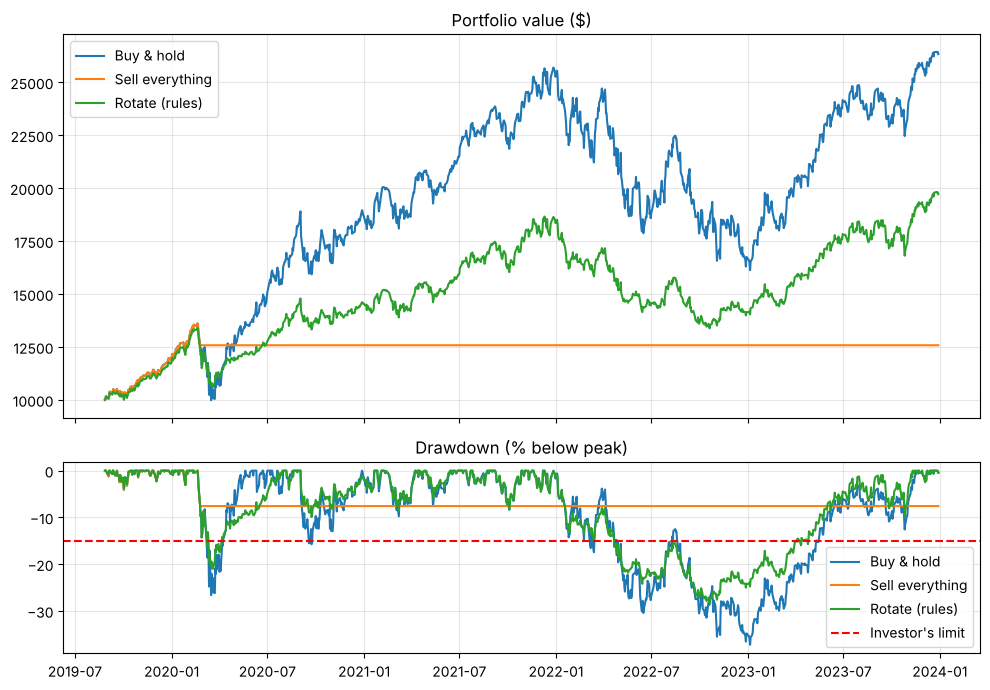

In [12]:
from backtester.metrics import drawdown_series

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for result in (hold, panic, rotate):
    top.plot(result.equity.index, result.equity, label=result.name)
    bottom.plot(result.equity.index, drawdown_series(result.equity) * 100, label=result.name)
bottom.axhline(-limits.max_drawdown * 100, color="red", linestyle="--", label="Investor's limit")
top.set_title("Portfolio value ($)"); bottom.set_title("Drawdown (% below peak)")
top.legend(); bottom.legend(); top.grid(alpha=0.3); bottom.grid(alpha=0.3)
fig.tight_layout()

**Read the table honestly:**
- Selling everything avoids most of the pain, and then misses everything that came after. Panic locks in the loss.
- Rotating gives up some return for a much calmer ride: lower volatility, smaller drawdown, fewer days beyond the daily limit.
- **No rule kept the drawdown inside 15%.** Decisions happen at the close and trades fill a day later, crashes gap, and in 2022 the "calm" bonds fell too. Limits are targets, not guarantees. Say this out loud to anyone who sells you a "guaranteed" stop.

### Inside the crises

In [13]:
risk.crisis_table({r.name: r.equity for r in (hold, panic, rotate)})

Return Worst fall
Crisis           Portfolio                         
2020 Covid crash Buy & hold        26.2%     -26.6%
                 Sell everything   -7.6%      -7.6%
                 Rotate (rules)     4.7%     -21.0%
2022 bear market Buy & hold       -34.5%     -36.2%
                 Sell everything    0.0%       0.0%
                 Rotate (rules)   -23.6%     -27.7%

### Every decision, with its reason

The log shows what the rules saw and what they did. This is what an investor should be able to read.

In [14]:
rotate.log[["date", "trigger", "reasons", "action", "turnover"]].head(12)

,date,trigger,reasons,action,turnover
0,2019-08-27,rotate,One-day VaR 3.07% is above the 3.00% budget.,rotate,0.3000
1,2019-09-11,NaN,Quiet for 10 days.,re-risk 5%,0.0911
2,2019-09-25,NaN,Quiet for 10 days.,re-risk 5%,0.1085
3,2019-10-29,NaN,Quiet for 10 days.,re-risk 5%,0.1229
4,2020-02-24,rotate,Drawdown -7.5% is past the rotate line of -7.5%. Today's loss of -4.3% is beyond the daily limit of -3.0%.,rotate,0.0351
5,2020-03-03,rotate,Drawdown -11.8% is past the rotate line of -7.5%. Today's loss of -3.4% is beyond the daily limit of -3.0%. One-day ...,rotate,0.5051
6,2020-03-11,emergency,Drawdown -16.1% is past the emergency line of -12.0%.,rotate,0.8756
7,2020-03-26,NaN,Quiet for 10 days.,re-risk 5%,0.1192
8,2020-04-06,rotate,One-day VaR 3.20% is above the 3.00% budget.,rotate,0.2037
9,2020-05-27,NaN,Quiet for 10 days.,re-risk 5%,0.1037


## 7. What drove a bad day: the market, or my holdings?

The **CAPM** split from the take-home project: a portfolio's move is partly the whole market (**beta** x the market's move) and partly down to its own holdings. Beta is estimated only from the six months **before** the day, so there is no look-ahead.

In [15]:
spy = load_closes(["SPY"], start="2019-06-01", end="2023-12-31")["SPY"].pct_change()
tech_daily = (prices[TECH].pct_change() * 0.2).sum(axis=1)
worst_day = tech_daily.loc["2020"].idxmin()
split = risk.capm_split(tech_daily, spy, worst_day)
print(f"Worst day of 2020: {worst_day:%Y-%m-%d}")
pd.Series({
    "Beta (how strongly it follows the market)": f"{split['beta']:.2f}",
    "Portfolio's move that day": f"{split['total']:.2%}",
    "Explained by the market": f"{split['market_part']:.2%}",
    "Down to our own holdings": f"{split['own_part']:.2%}",
}).to_frame(f"{worst_day:%Y-%m-%d}")

Worst day of 2020: 2020-03-16


,2020-03-16
Beta (how strongly it follows the market),1.05
Portfolio's move that day,-11.32%
Explained by the market,-11.50%
Down to our own holdings,0.18%


In [16]:
risk.unusual_moves(prices.pct_change(), worst_day).round(3)

,return,z_score,spike_ratio
XLU,-0.114,-4.883,2.297
QQQ,-0.120,-4.546,2.256
XLV,-0.099,-4.470,2.229
MSFT,-0.147,-4.413,2.260
GOOGL,-0.116,-4.279,2.100
AAPL,-0.129,-3.795,2.174
XLP,-0.068,-2.903,2.373
AMZN,-0.054,-2.124,1.896
GLD,-0.011,-1.035,1.985
TLT,0.065,4.387,1.931


A **z-score** below -3 means the move was far outside its usual range. A **spike ratio** above 1.5 means volatility has jumped recently. Notebook 06 uses these to decide when the AI model is worth asking at all.

## 8. What if?

Take an ordinary day and pretend some holdings crashed. `what_if` rewrites that one day; `decide_on` shows what the lines and the manager would do.

In [17]:
DAY = "2021-06-15"
shocked = risk.what_if(prices, DAY, {"AAPL": -0.12, "MSFT": -0.10, "QQQ": -0.08})
decision = risk.decide_on(shocked, start, DAY, limits, calm=CALM)
print("Trigger:", decision["trigger"], "|", " ".join(decision["reasons"]))
print("Plan:", decision["plan"])
print("Passes the check:", decision["check"].passed if decision["check"] else "no plan")

Trigger: rotate | Today's loss of -6.2% is beyond the daily limit of -3.0%. One-day VaR 3.25% is above the 3.00% budget.
Plan: {'AAPL': 0.15, 'MSFT': 0.15, 'AMZN': 0.2, 'GOOGL': 0.2, 'QQQ': 0.15, 'IEF': 0.15}
Passes the check: True


## 9. ✏️ Your turn

Change the cells above, or the one below, and re-run:
- Tighten the limits to 10% and 2%. What happens to the number of trades and the costs?
- Remove the bonds from `CALM`. Does rotating still help in 2022?
- Write your own manager: a function that takes `context` and returns a dict of weights (or `None` to hold). Look at `context.keys()` to see what it can use.

In [18]:
def my_manager(context):
    if context["trigger"] is None:
        return None
    return {"QQQ": 0.4, "TLT": 0.3, "GLD": 0.3}

mine = risk.run_guarded(prices, start, limits, manager=my_manager, calm=CALM, name="My manager")
risk.compare([hold, rotate, mine])

,Buy & hold,Rotate (rules),My manager
Total return,163.3%,97.2%,70.0%
Annual return (CAGR),25.0%,16.9%,13.0%
Annual volatility,28.3%,17.4%,15.3%
Sharpe ratio,0.93,0.99,0.87
Max drawdown,-37.2%,-28.3%,-29.3%
Number of trades,0,77,82
Days over daily limit,45,12,8
Worst day,-11.5%,-5.8%,-4.7%
Costs paid,0.0%,0.6%,0.7%


**Questions to discuss:**
- Is a lower return with a much smaller drawdown a better portfolio? For whom?
- Which assets are truly "calm"? Were they calm in 2022?
- Our rules were tuned by looking at 2020 and 2022. How would you test them fairly?

### Next: let an AI model manage it, inside the rules

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/06_ai_risk_agent.ipynb) `06_ai_risk_agent.ipynb`